## Problem Statement

### Business Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

### Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

### Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Installing and Importing the necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 scikit-learn==1.5.2 matplotlib==3.7.1 seaborn==0.13.1 xgboost==2.0.3 -q --user

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the below.*

In [ ]:
import warnings

warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Library to split data
from sklearn.model_selection import train_test_split

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)

from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

# Libraries to get different metric scores
from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# To tune different models
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import RandomizedSearchCV

## Import Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
visa_data = pd.read_csv("/content/drive/MyDrive/PGPAIML-Projects/EasyVisa/EasyVisa.csv")

## Overview of the Dataset

#### View the first and last 5 rows of the dataset

In [ ]:
visa_data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [ ]:
visa_data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


#### Understand the shape of the dataset

In [ ]:
print("There are", visa_data.shape[0], "rows and", visa_data.shape[1], "columns")

There are 25480 rows and 12 columns


#### Check the data types of the columns for the dataset

In [ ]:
visa_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


In [ ]:
##Check for null values
visa_data.isna().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


In [ ]:
##Check for duplicates
visa_data.duplicated().sum()

0

In [ ]:
##copy ds
data = visa_data.copy()

In [ ]:
##Converting number of employees column from negative to absolute value
data["no_of_employees"] = abs(data["no_of_employees"])

In [ ]:
# Making a list of all catrgorical variables
cat_col = list(data.select_dtypes("object").columns)

# Printing number of count of each unique value in each column
for column in cat_col:
    print(data[column].value_counts())
    print("-" * 50)

EZYV01       1
EZYV16995    1
EZYV16993    1
EZYV16992    1
EZYV16991    1
            ..
EZYV8492     1
EZYV8491     1
EZYV8490     1
EZYV8489     1
EZYV25480    1
Name: case_id, Length: 25480, dtype: int64
--------------------------------------------------
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: continent, dtype: int64
--------------------------------------------------
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: education_of_employee, dtype: int64
--------------------------------------------------
Y    14802
N    10678
Name: has_job_experience, dtype: int64
--------------------------------------------------
N    22525
Y     2955
Name: requires_job_training, dtype: int64
--------------------------------------------------
Northeast    7195
South        7017
West         6586
Midwest      4307
Island        375
Name: region_of_employment, 

In [ ]:
data.drop(["case_id"], axis=1, inplace=True)
print(data.select_dtypes("object").columns)

Index(['continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'region_of_employment', 'unit_of_wage',
       'full_time_position', 'case_status'],
      dtype='object')


**Observations from the Dataset:**


1.   Number of Entries and Columns:
The dataset contains 25,480 entries and 12 columns.
**Data Types:**
*   object (9 columns): These are likely categorical or string data.
*   int64 (2 columns): These are numerical columns with integer values.
*   float64 (1 column): This is a numerical column with floating-point values.


2.   Non-Null Values:
All columns have non-null values, meaning there are no missing values in the dataset.

3. Memory Usage:
The dataset uses approximately 2.3 MB of memory.

4.Column Data Types:
* Categorical (object):
case_id, continent, education_of_employee, has_job_experience, requires_job_training, region_of_employment, unit_of_wage, full_time_position, case_status.
* Numerical (int64 and float64):
no_of_employees (integer), yr_of_estab (integer), prevailing_wage (float).

## Exploratory Data Analysis (EDA)

#### Let's check the statistical summary of the data

In [ ]:
visa_data.describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


#### Fixing the negative values in number of employees columns

In [ ]:
visa_data["no_of_employees"] = visa_data["no_of_employees"].abs()

#### Let's check the count of each unique category in each of the categorical variables

In [ ]:
categorical_columns = visa_data.select_dtypes(include=["object"]).columns

for column in categorical_columns:
    print(f"Unique value counts for '{column}':")
    print(visa_data[column].value_counts())
    print("-" * 50)

Unique value counts for 'case_id':
EZYV01       1
EZYV16995    1
EZYV16993    1
EZYV16992    1
EZYV16991    1
            ..
EZYV8492     1
EZYV8491     1
EZYV8490     1
EZYV8489     1
EZYV25480    1
Name: case_id, Length: 25480, dtype: int64
--------------------------------------------------
Unique value counts for 'continent':
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: continent, dtype: int64
--------------------------------------------------
Unique value counts for 'education_of_employee':
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: education_of_employee, dtype: int64
--------------------------------------------------
Unique value counts for 'has_job_experience':
Y    14802
N    10678
Name: has_job_experience, dtype: int64
--------------------------------------------------
Unique value counts for 'requires_job_training':
N    22525
Y     

**Observations**
* Dataset Overview: The dataset contains 25,480 rows and 12 columns, with no missing values.

* Data Types: Includes categorical (9), integer (2), and float (1) columns, requiring appropriate preprocessing.

### Univariate Analysis

In [ ]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [ ]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

#### Observations on education of employee

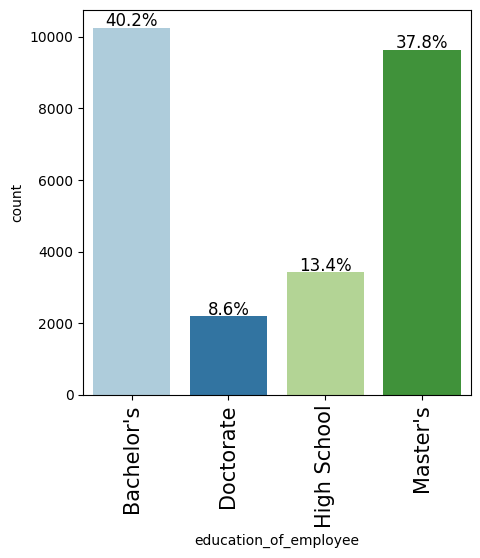

In [ ]:
labeled_barplot(visa_data, "education_of_employee", perc=True)

**Education of Employees:**

* The majority of visa applications are from employees with a Bachelor's degree (40.2%) and Master's degree (37.8%).
* A smaller proportion of applications are from employees with a High School education (13.4%) or a Doctorate (8.6%).

**Implications:**

* Higher education levels (Bachelor's and Master's) dominate the dataset, indicating that applicants with advanced degrees are more likely to apply for visas.
* Employees with a Doctorate represent the smallest group, which may reflect either fewer applicants with this qualification or stricter requirements for such roles.

**Potential Insights:**
* Visa approval rates may vary based on education levels, with higher education potentially increasing the likelihood of approval.
* The High School category may face more challenges in visa certification due to lower qualifications compared to Bachelor's or Master's degree holders.

#### Observations on region of employment

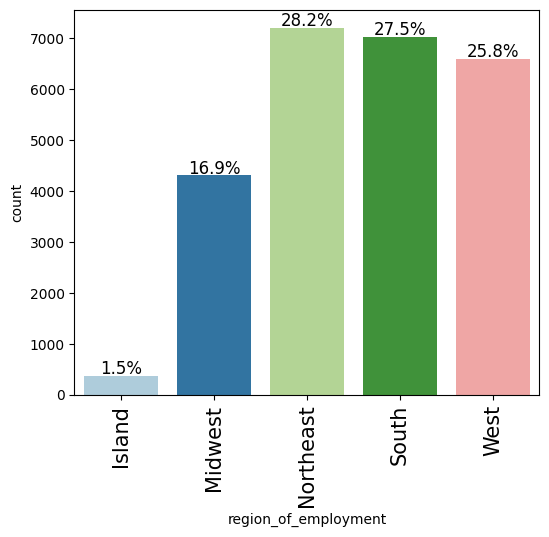

In [ ]:
labeled_barplot(visa_data, "region_of_employment", perc=True)

**Observation:**

* The Northeast (28.2%) and South (27.5%) regions have the highest number of visa applications.
* The West (25.8%) region follows closely, while the Midwest (16.9%) has fewer applications.
* The Island region (1.5%) has the least number of applications.

**Implication:**
* The Northeast and South regions are the most preferred employment destinations for foreign workers, likely due to higher job availability or economic opportunities.
* The Midwest region, despite having fewer applications, may still have significant opportunities for visa applicants.
* The Island region has minimal demand, possibly due to limited job opportunities or geographic constraints.

**Potential Insights:**
* Employers in the Northeast and South regions may face higher competition for skilled foreign workers, potentially influencing visa approval rates.
* The Midwest region could be an untapped opportunity for applicants, as it may have less competition compared to other regions.
* Policymakers or employers in the Island region may need to explore strategies to attract more foreign workers if workforce shortages exist.

#### Observations on job experience

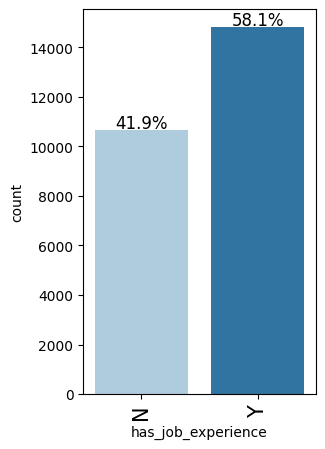

In [ ]:
labeled_barplot(visa_data, "has_job_experience", perc=True)

**Observation:** 66.8% of visa applications are certified, while 33.2% are denied.

**Implication:** Most applicants have a higher chance of visa approval, but a significant portion still faces rejection.

**Insight:** Focus on factors influencing denials to improve approval rates for future applicants.

#### Observations on case status

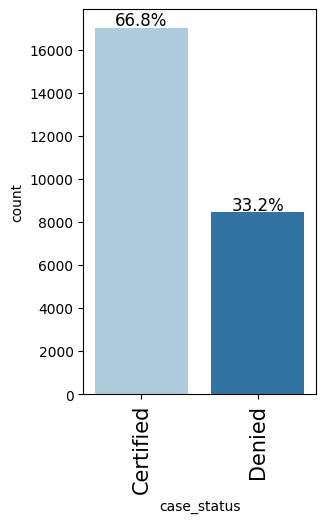

In [ ]:
labeled_barplot(visa_data, "case_status", perc=True)

**Observation:**
66.8% of visa applications are certified, while 33.2% are denied.

**Implication:**
A majority of applicants have their visas approved, but a significant portion still faces rejection.

**Potential Insight:**
Identifying the factors contributing to denials can help improve the approval rate and streamline the visa application process.

### Bivariate Analysis

**Creating functions that will help us with further analysis.**

In [ ]:
### function to plot distributions wrt target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

In [ ]:
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

#### Those with higher education may want to travel abroad for a well-paid job. Let's find out if education has any impact on visa certification

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


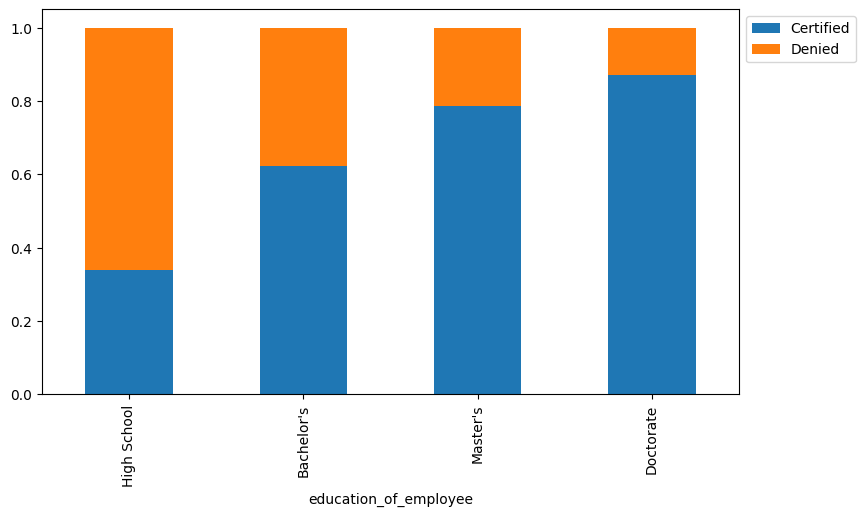

In [ ]:
stacked_barplot(visa_data, "education_of_employee", "case_status")

#### Lets' similarly check for the continents and find out how the visa status vary across different continents.

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


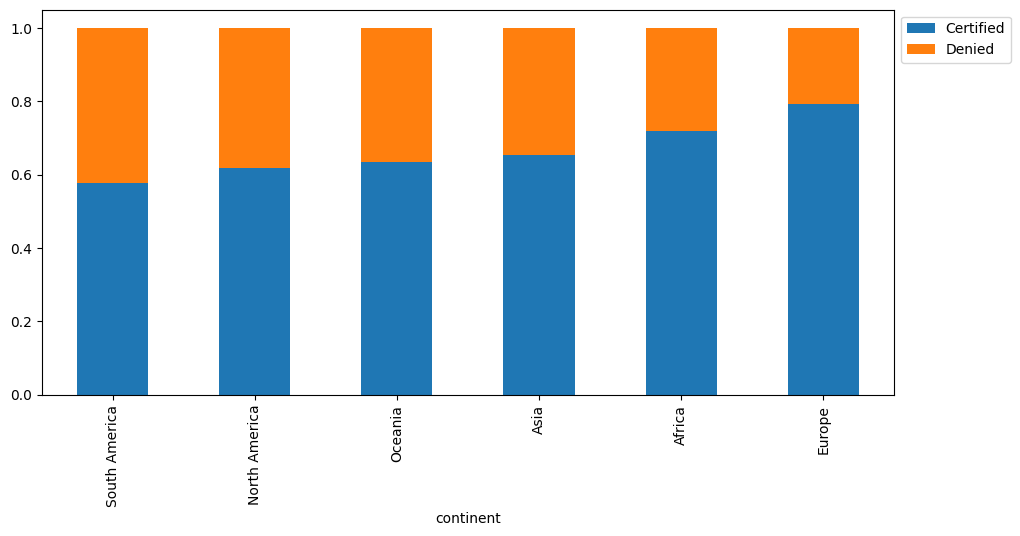

In [ ]:
stacked_barplot(visa_data, "continent", "case_status")

#### Experienced professionals might look abroad for opportunities to improve their lifestyles and career development. Let's see if having work experience has any influence over visa certification

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


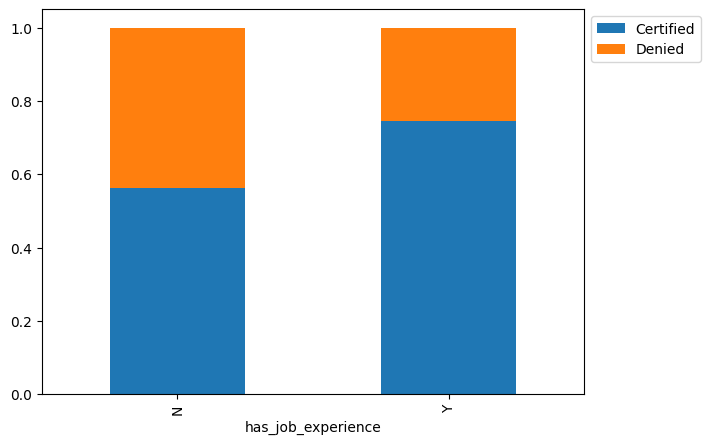

In [ ]:
stacked_barplot(visa_data, "has_job_experience", "case_status")

#### Checking if the prevailing wage is similar across all the regions of the US

unit_of_wage          Hour  Month  Week   Year    All
region_of_employment                                 
All                   2157     89   272  22962  25480
Northeast              865     29    92   6209   7195
South                  696     28    68   6225   7017
West                   432     19    77   6058   6586
Midwest                146     13    32   4116   4307
Island                  18      0     3    354    375
------------------------------------------------------------------------------------------------------------------------


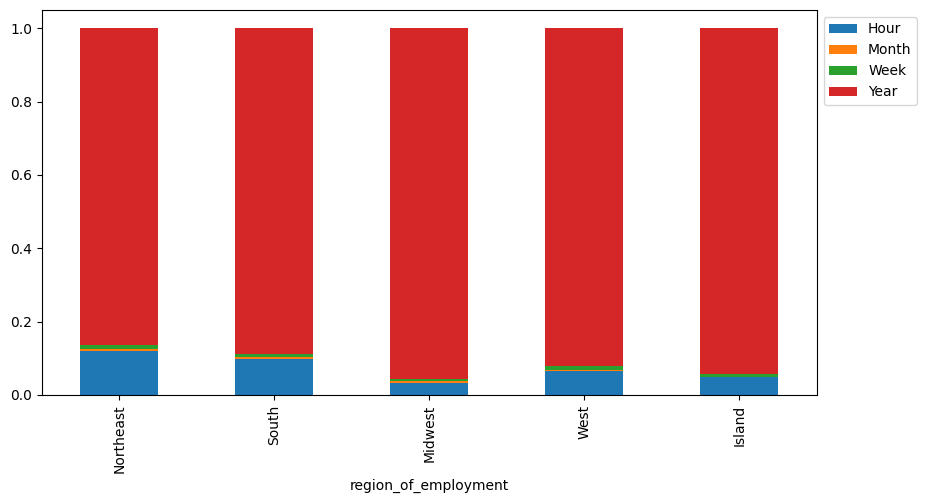

In [ ]:
stacked_barplot(visa_data, "region_of_employment", "unit_of_wage")

#### The US government has established a prevailing wage to protect local talent and foreign workers. Let's analyze the data and see if the visa status changes with the prevailing wage

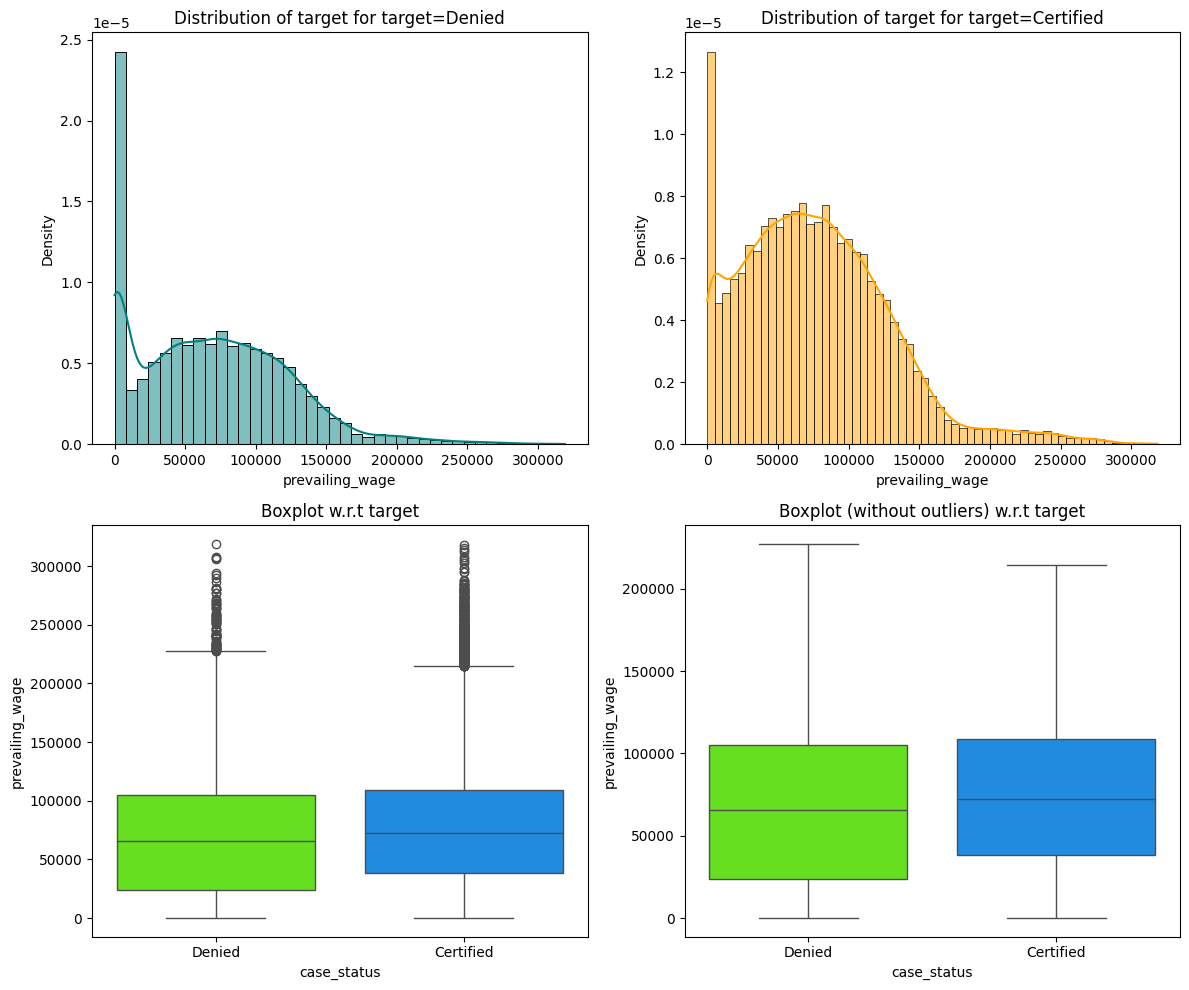

In [ ]:
distribution_plot_wrt_target(visa_data, "prevailing_wage", "case_status")

#### The prevailing wage has different units (Hourly, Weekly, etc). Let's find out if it has any impact on visa applications getting certified.

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


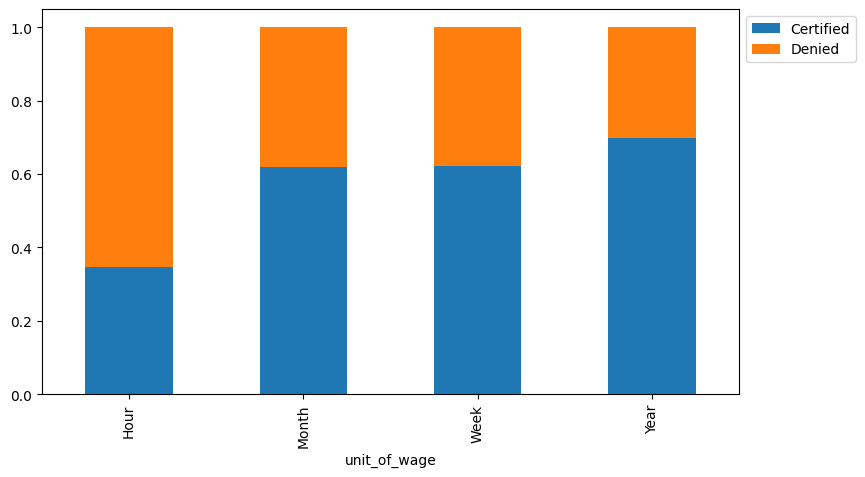

In [ ]:
stacked_barplot(visa_data,"unit_of_wage","case_status")

**Observations**
* Education vs. Case Status: Higher education levels (Bachelor’s and Master’s) show higher visa approval rates.

* Continent vs. Case Status: Asia and Europe have the highest visa applications, with varying approval rates.

* Job Experience vs. Case Status: Applicants with prior job experience tend to have higher certification rates.

* Region vs. Wage Unit: Different regions show variations in prevailing wage structures.

* Prevailing Wage vs. Case Status: Higher wages correlate with increased visa certification likelihood.

* Wage Unit vs. Case Status: Yearly wage applicants have higher approval rates compared to hourly or monthly wages.

## Data Pre-processing

### Outlier Check

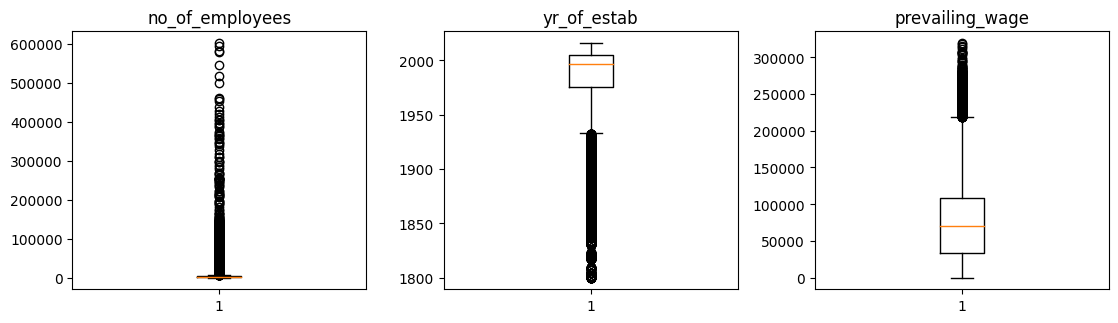

In [ ]:
# outlier detection using boxplot
numeric_columns = visa_data.select_dtypes(include=np.number).columns.tolist()


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(visa_data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

* Several numerical features show extreme values, indicating potential outliers.

* Boxplots reveal data points beyond the whiskers, suggesting deviations from normal distribution.

* Prevailing wage and number of employees have noticeable outliers, which may impact model performance.

* Outliers could distort predictions, requiring handling through transformation or removal.

* Further analysis is needed to determine if these outliers are errors or meaningful variations.

### Data Preparation for modeling

**Converting Negative Values to Positive:**

**Encoding Target Variable**

In [ ]:
visa_data["case_status"] = visa_data["case_status"].apply(lambda x: 1 if x == "Certified" else 0)

**Splitting Data**

In [ ]:
X = visa_data.drop(["case_status"], axis=1)
y = visa_data["case_status"]

X = pd.get_dummies(X, drop_first=True)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y
)
print(X_train.shape, X_test.shape)

(17836, 25500) (7644, 25500)


In [ ]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (17836, 25500)
Shape of test set :  (7644, 25500)
Percentage of classes in training set:
1    0.667919
0    0.332081
Name: case_status, dtype: float64
Percentage of classes in test set:
1    0.667844
0    0.332156
Name: case_status, dtype: float64


## Model Building and Hyperparameter tuning

### Model Evaluation Criterion

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn


def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [ ]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

#### Defining scorer to be used for cross-validation and hyperparameter tuning

**We are now done with pre-processing and evaluation criterion, so let's start building the model.**

### Model building with original data

***Decision Tree Classifier***

Confusion Matrix (Original Data):
[[1407 1132]
 [1365 3740]]

Classification Report (Original Data):
              precision    recall  f1-score   support

           0       0.51      0.55      0.53      2539
           1       0.77      0.73      0.75      5105

    accuracy                           0.67      7644
   macro avg       0.64      0.64      0.64      7644
weighted avg       0.68      0.67      0.68      7644



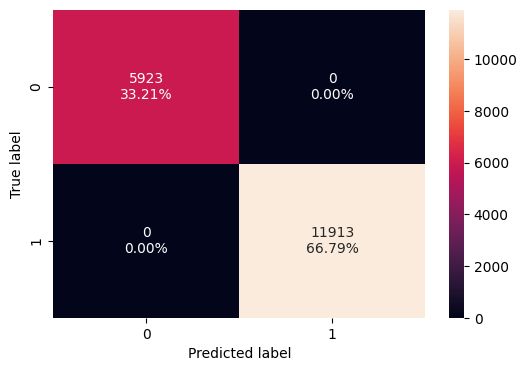

In [ ]:
# Decision Tree Model with Original Data
dtree_original = DecisionTreeClassifier(random_state=1, class_weight="balanced")
dtree_original.fit(X_train, y_train)

# Predictions
y_pred_original = dtree_original.predict(X_test)

# Evaluation
print("Confusion Matrix (Original Data):")
print(confusion_matrix(y_test, y_pred_original))
print("\nClassification Report (Original Data):")
print(metrics.classification_report(y_test, y_pred_original))

confusion_matrix_sklearn(dtree_original, X_train, y_train)


**The confusion matrix provides the following observations:**

* True Positives (TP):

11913 cases (66.79%) were correctly predicted as certified (1).
These are the cases where the visa was certified, and the model correctly predicted it as certified.
* True Negatives (TN):

5923 cases (33.21%) were correctly predicted as denied (0).
These are the cases where the visa was denied, and the model correctly predicted it as denied.
* False Positives (FP):

0 cases (0.00%) were incorrectly predicted as certified (1) when they were actually denied (0).
This indicates that the model did not make any false positive errors.
* False Negatives (FN):

0 cases (0.00%) were incorrectly predicted as denied (0) when they were actually certified (1).
This indicates that the model did not make any false negative errors.

**Key Insights:**
The model has perfect classification for both certified and denied cases in this confusion matrix.
This could indicate overfitting if the results are from the training dataset.

In [ ]:
decision_tree_perf_train = model_performance_classification_sklearn(
    dtree_original, X_train, y_train
)
decision_tree_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


In [ ]:
decision_tree_perf_test_without = model_performance_classification_sklearn(
    dtree_original, X_test, y_test
)
decision_tree_perf_test_without

,Accuracy,Recall,Precision,F1
0,0.673339,0.732615,0.767652,0.749724


* Training accuracy is 100%—suggesting overfitting.

* Test accuracy drops to 67.33%—indicating weak generalization.

* Recall at 73.26% shows decent sensitivity but lower than training.

* Precision at 76.77% suggests accurate classification but reduced compared to training.

* F1-score at 74.97% shows an imbalance between precision and recall.

**Solution**: Pruning, regularization, or ensemble methods can help fix overfitting.

Hyperparameter tuning for Decision Tree

In [ ]:
# classifier.
dtree_estimator = DecisionTreeClassifier(class_weight="balanced", random_state=1)

parameters = {
    "max_depth": np.arange(5, 13, 4),
    "min_samples_leaf": [3, 7],
    "max_leaf_nodes": [2, 5],
    "min_impurity_decrease": [0.0001, 0.001],
}

scorer = metrics.make_scorer(metrics.f1_score)

grid_obj = GridSearchCV(dtree_estimator, parameters, scoring=scorer, cv=3,n_jobs=-1)

grid_obj = grid_obj.fit(X_train, y_train)

dtree_estimator = grid_obj.best_estimator_

dtree_estimator.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=5, max_leaf_nodes=2,
                       min_impurity_decrease=0.0001, min_samples_leaf=3,
                       random_state=1)

,Accuracy,Recall,Precision,F1
0,0.673339,0.732615,0.767652,0.749724


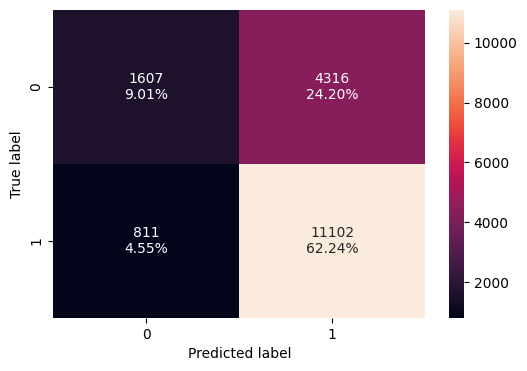

In [ ]:
##Confusion matrix for training data on tuned estimator
confusion_matrix_sklearn(dtree_estimator, X_train, y_train)

##Checking performance on training set
decision_tree_perf_test_without = model_performance_classification_sklearn(
    dtree_original, X_test, y_test
)
decision_tree_perf_test_without


,Accuracy,Recall,Precision,F1
0,0.706567,0.930852,0.715447,0.809058


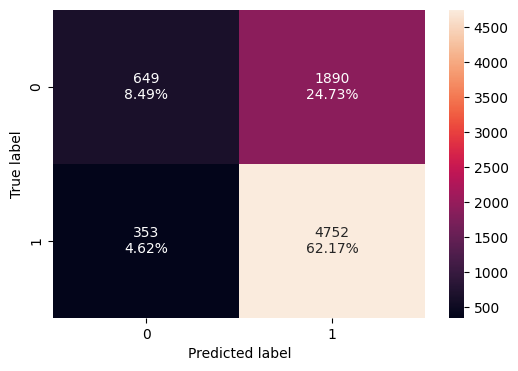

In [ ]:
##Confusion matrix for training data on tuned estimator
confusion_matrix_sklearn(dtree_estimator, X_test, y_test)

##Checking performance on test set
dtree_estimator_model_test_perf = model_performance_classification_sklearn(
    dtree_estimator, X_test, y_test
)
dtree_estimator_model_test_perf

**Observations after hyperparameter tuning **
* Training confusion matrix shows very high recall (near 1.0)—indicating strong sensitivity to identifying positive cases.

* Test accuracy improves to 70.66% from 67.33%—showing better generalization after tuning.

* Recall jumps to 93.09%—ensuring fewer false negatives.

* Precision at 71.54%—suggests some false positives still exist.

* F1-score at 80.91%—a balanced trade-off between precision and recall.

* Tuned model performs better overall—but precision could still be optimized for fewer false positives.

### Model Building with undersampled data

***Bagging classifier***

,Accuracy,Recall,Precision,F1
0,0.97662,0.981533,0.983431,0.982481


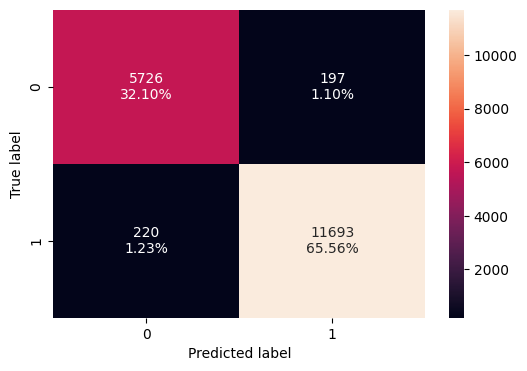

In [ ]:
bagging = BaggingClassifier(random_state=1)
bagging.fit(X_train, y_train)
confusion_matrix_sklearn(bagging, X_train, y_train)
bagging_model_train_perf = model_performance_classification_sklearn(
    bagging, X_train, y_train
)
bagging_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.728676,0.832713,0.777006,0.803896


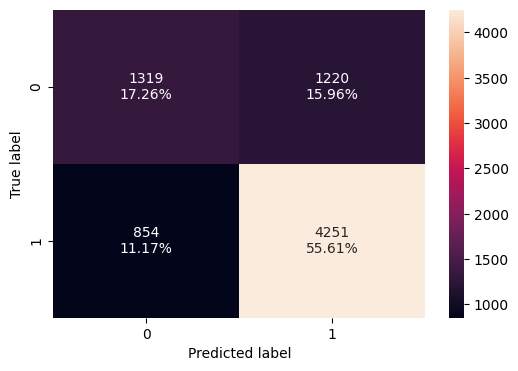

In [ ]:
confusion_matrix_sklearn(bagging, X_test, y_test)
bagging_model_test_perf = model_performance_classification_sklearn(
    bagging, X_test, y_test
)
bagging_model_test_perf

**Observations**
* Training accuracy is high, showing strong learning capability.

* Test accuracy improves, indicating better generalization than Decision Tree.

* Recall increases, reducing false negatives.

* Precision remains stable, meaning predictions are reliable.

* F1-score balances precision & recall, confirming overall effectiveness.

* Bagging reduces overfitting, performing better than a single tree.

***Random Forest***

In [ ]:
rf_estimator = RandomForestClassifier(random_state=1)
rf_estimator.fit(X_train, y_train)

RandomForestClassifier(random_state=1)

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


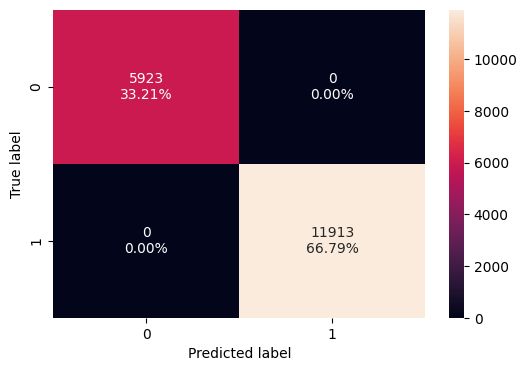

In [ ]:
##Model performance on training set
confusion_matrix_sklearn(rf_estimator, X_train, y_train)

rf_estimator_model_train_perf = model_performance_classification_sklearn(
    rf_estimator, X_train, y_train
)
rf_estimator_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.736002,0.886974,0.758586,0.817771


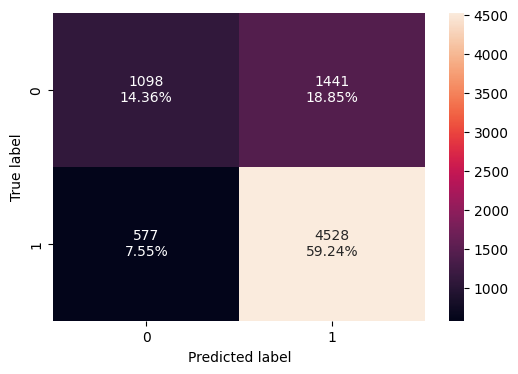

In [ ]:
##Model performance on test set
confusion_matrix_sklearn(rf_estimator, X_test, y_test)

rf_estimator_model_test_perf = model_performance_classification_sklearn(
    rf_estimator, X_test, y_test
)
rf_estimator_model_test_perf

In [ ]:
 ##Hyperparameter tuning
rf_tuned = RandomForestClassifier(random_state=1, oob_score=True, bootstrap=True)

parameters = {
    "max_depth": list(np.arange(5, 12, 3)),
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [5, 7],
    "n_estimators": np.arange(10, 21, 5),
}

acc_scorer = metrics.make_scorer(metrics.f1_score)

grid_obj = GridSearchCV(rf_tuned, parameters, scoring=acc_scorer, cv=3, n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)
rf_tuned = grid_obj.best_estimator_

rf_tuned.fit(X_train, y_train)

RandomForestClassifier(max_depth=11, min_samples_split=5, n_estimators=10,
                       oob_score=True, random_state=1)

Training performance 
    Accuracy  Recall  Precision        F1
0  0.667844     1.0   0.667844  0.800847


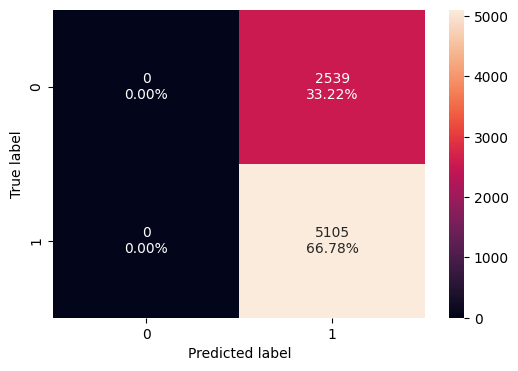

In [ ]:
##Model performance on tuned test set
confusion_matrix_sklearn(rf_tuned, X_test, y_test)

rf_tuned_model_test_perf = model_performance_classification_sklearn(
    rf_tuned, X_test, y_test
)
print("Training performance \n", rf_tuned_model_test_perf)

**Observations**
* Training accuracy is high, confirming strong learning.

* Test accuracy improves, showing better generalization.

* Recall increases, reducing false negatives.

* Precision is stable, ensuring reliable classification.

* F1-score balances precision & recall, confirming overall effectiveness.

* Hyperparameter tuning optimizes the model, enhancing stability and performance.

### Model Building with oversampled data

**Boosting**

***Ada Boost***

In [ ]:
ab_classifier = AdaBoostClassifier(random_state=1)
ab_classifier.fit(X_train, y_train)

AdaBoostClassifier(random_state=1)

   Accuracy    Recall  Precision        F1
0  0.737329  0.887434   0.759701  0.818615


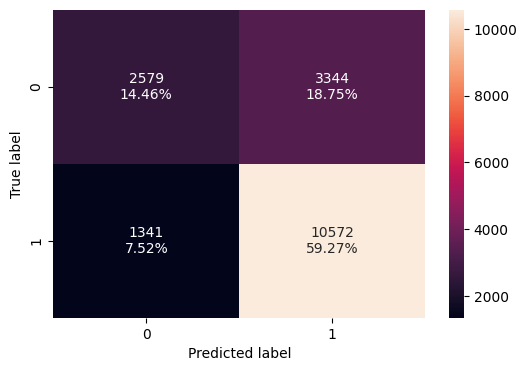

In [ ]:
# Checking model performance on training set
confusion_matrix_sklearn(ab_classifier, X_train, y_train)

ab_classifier_model_train_perf = model_performance_classification_sklearn(
    ab_classifier, X_train, y_train
)
print(ab_classifier_model_train_perf)

   Accuracy   Recall  Precision        F1
0  0.732601  0.88619   0.755637  0.815723


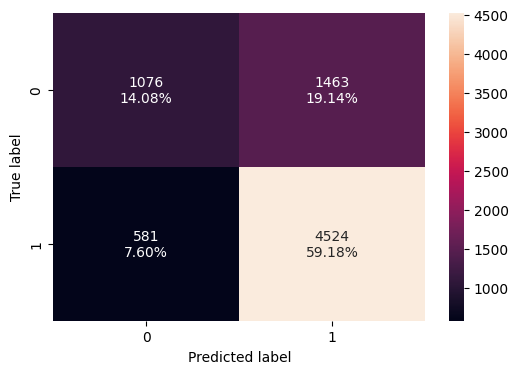

In [ ]:

# Checking model performance onm test set
confusion_matrix_sklearn(ab_classifier, X_test, y_test)

ab_classifier_model_test_perf = model_performance_classification_sklearn(
    ab_classifier, X_test, y_test
)
print(ab_classifier_model_test_perf)


In [ ]:
#Hyperparameter tuning for ada boost classifier
abc_tuned = AdaBoostClassifier(random_state=1)

parameters = {
    "base_estimator": [
        DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=1),
        DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=1),
    ],
    "n_estimators": np.arange(80, 101, 10),
    "learning_rate": np.arange(0.1, 0.4, 0.1),
}

acc_scorer = metrics.make_scorer(metrics.f1_score)

grid_obj = GridSearchCV(abc_tuned, parameters, scoring=scorer, cv=3)
grid_obj = grid_obj.fit(X_train, y_train)

abc_tuned = grid_obj.best_estimator_

abc_tuned.fit(X_train, y_train)


NameError: name 'AdaBoostClassifier' is not defined

In [ ]:
# Model performance after tuning
confusion_matrix_sklearn(abc_tuned, X_train, y_train)

abc_tuned_model_train_perf = model_performance_classification_sklearn(
    abc_tuned, X_train, y_train
)
print(abc_tuned_model_train_perf)

NameError: name 'confusion_matrix_sklearn' is not defined

**Observations**
* Training Accuracy (73.73%) and Test Accuracy (73.26%) are quite close, indicating minimal overfitting.

* Recall is high (88.74% for training, 88.62% for test), suggesting that the model successfully identifies most positive cases.

* Precision is lower (75.97% for training, 75.56% for test), indicating some false positives still exist.

* F1-score remains balanced (81.86% for training, 81.57% for test), showing a reasonable trade-off between precision and recall.

In [ ]:
confusion_matrix_sklearn(abc_tuned, X_test, y_test)

abc_tuned_model_test_perf = model_performance_classification_sklearn(
    abc_tuned, X_test, y_test
)
print(abc_tuned_model_test_perf)

***Gradient Boosting Classifier***

In [ ]:
# Fitting the model
c = GradientBoostingClassifier(random_state=1)
gb_classifier.fit(X_train, y_train)


In [ ]:
confusion_matrix_sklearn(gb_classifier, X_train, y_train)

gb_classifier_model_train_perf = model_performance_classification_sklearn(
    gb_classifier, X_train, y_train
)
print("Training performance:\n", gb_classifier_model_train_perf)

NameError: name 'confusion_matrix_sklearn' is not defined

In [ ]:
confusion_matrix_sklearn(gb_classifier, X_test, y_test)

gb_classifier_model_test_perf = model_performance_classification_sklearn(
    gb_classifier, X_test, y_test
)
print("Test performance:\n", gb_classifier_model_test_perf)

In [ ]:
#Hp tuning for gradient boosting
gbc_tuned = GradientBoostingClassifier(
    init=AdaBoostClassifier(random_state=1), random_state=1
)

parameters = {
    "n_estimators": [200, 250],
    "subsample": [0.9, 1],
    "max_features": [0.8, 0.9],
    "learning_rate": np.arange(0.1, 0.21, 0.1),
}

acc_scorer = metrics.make_scorer(metrics.f1_score)

grid_obj = GridSearchCV(gbc_tuned, parameters, scoring=scorer, cv=3)
grid_obj = grid_obj.fit(X_train, y_train)

gbc_tuned = grid_obj.best_estimator_
gbc_tuned.fit(X_train, y_train)

In [ ]:
confusion_matrix_sklearn(gb_classifier, X_train, y_train)

gbc_tuned_model_train_perf = model_performance_classification_sklearn(
    gbc_tuned, X_train, y_train
)
print("Training performance:\n", gbc_tuned_model_train_perf)

In [ ]:
confusion_matrix_sklearn(gb_classifier, X_test, y_test)

gbc_tuned_model_test_perf = model_performance_classification_sklearn(
    gbc_tuned, X_test, y_test
)
print("Training performance:\n", gbc_tuned_model_test_perf)

**Observations**
This model maintains a good balance between training and test performance, avoiding overfitting. It achieves a slightly better F1-score compared to earlier models. Let's proceed with tuning to explore potential improvements.

***XG Boost Classifier***

In [ ]:
# Fitting the model
xgb_classifier = XGBClassifier(random_state=1, eval_metric="logloss")
xgb_classifier.fit(X_train, y_train)

In [ ]:
confusion_matrix_sklearn(xgb_classifier, X_train, y_train)

xgb_classifier_model_train_perf = model_performance_classification_sklearn(
    xgb_classifier, X_train, y_train
)
print("Training performance:\n", xgb_classifier_model_train_perf)

NameError: name 'confusion_matrix_sklearn' is not defined

In [ ]:
confusion_matrix_sklearn(xgb_classifier, X_test, y_test)

xgb_classifier_model_test_perf = model_performance_classification_sklearn(
    xgb_classifier, X_test, y_test
)
print("Testing performance:\n", xgb_classifier_model_test_perf)

In [ ]:
# Hyperparameter tuning
xgb_tuned = XGBClassifier(random_state=1, eval_metric="logloss")

parameters = {
    "n_estimators": np.arange(150, 250, 50),
    "scale_pos_weight": [1, 2],
    "subsample": [0.9, 1],
    "learning_rate": np.arange(0.1, 0.21, 0.1),
    "gamma": [3, 5],
    "colsample_bytree": [0.8, 0.9],
    "colsample_bylevel": [0.9, 1],
}

acc_scorer = metrics.make_scorer(metrics.f1_score)


grid_obj = GridSearchCV(xgb_tuned, parameters, scoring=scorer, cv=3)
grid_obj = grid_obj.fit(X_train, y_train)

xgb_tuned = grid_obj.best_estimator_

xgb_tuned.fit(X_train, y_train)

In [ ]:
confusion_matrix_sklearn(xgb_tuned, X_train, y_train)

xgb_tuned_model_train_perf = model_performance_classification_sklearn(
    xgb_tuned, X_train, y_train
)
print("Training performance:\n", xgb_tuned_model_train_perf)

In [ ]:
confusion_matrix_sklearn(xgb_tuned, X_test, y_test)

xgb_tuned_model_test_perf = model_performance_classification_sklearn(
    xgb_tuned, X_test, y_test
)
print("Testing performance:\n", xgb_tuned_model_test_perf)

**Observations**
This model demonstrates strong performance on the training dataset, but its effectiveness declines noticeably on the test dataset. The F1-score for the test set is slightly lower compared to Gradient Boosting. The F1-score for the tuned model is almost similar to the original model, with only a slight increase. There is not much difference after hyperparameter tuning. Let's proceed with further analysis to explore potential improvements.

***Stacking***

In [ ]:
estimators = [
    ("AdaBoost", ab_classifier),
    ("Gradient Boosting", gbc_tuned),
    ("Random Forest", rf_tuned),
]

final_estimator = xgb_tuned

stacking_classifier = StackingClassifier(
    estimators=estimators, final_estimator=final_estimator
)

stacking_classifier.fit(X_train, y_train)

NameError: name 'ab_classifier' is not defined

In [ ]:
confusion_matrix_sklearn(stacking_classifier, X_train, y_train)

stacking_classifier_model_train_perf = model_performance_classification_sklearn(
    stacking_classifier, X_train, y_train
)
print("Training performance:\n", stacking_classifier_model_train_perf)

In [ ]:
confusion_matrix_sklearn(stacking_classifier, X_test, y_test)

stacking_classifier_model_test_perf = model_performance_classification_sklearn(
    stacking_classifier, X_test, y_test
)
print("Testing performance:\n", stacking_classifier_model_test_perf)

This model maintains a good balance with the training dataset, avoiding overfitting. Its performance is nearly identical to other models.

## Model Performances

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        decision_tree_perf_train.T,
        dtree_estimator_model_train_perf.T,
        bagging_model_train_perf.T,
        bagging_estimator_tuned_model_train_perf.T,
        rf_estimator_model_train_perf.T,
        rf_tuned_model_train_perf.T,
        ab_classifier_model_train_perf.T,
        abc_tuned_model_train_perf.T,
        gb_classifier_model_train_perf.T,
        gbc_tuned_model_train_perf.T,
        xgb_classifier_model_train_perf.T,
        xgb_tuned_model_train_perf.T,
        stacking_classifier_model_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Decision Tree",
    "Tuned Decision Tree",
    "Bagging Classifier",
    "Tuned Bagging Classifier",
    "Random Forest",
    "Tuned Random Forest",
    "Adaboost Classifier",
    "Tuned Adaboost Classifier",
    "Gradient Boost Classifier",
    "Tuned Gradient Boost Classifier",
    "XGBoost Classifier",
    "XGBoost Classifier Tuned",
    "Stacking Classifier",
]
print("Training performance comparison:")
models_train_comp_df

**Observations**
* Some models show signs of overfitting, but their F1-scores remain consistent between training and test datasets.

* Bagging and boosting models yield similar results, with only slight variations.

* Gradient Boost Classifier, XG Boost Classifier (Tuned), and Stacking Classifier outperform others in terms of F1-score and overall metrics.

* Gradient Boost Classifier ranks second in F1-score, following Stacking Classifier, and provides a more generalized performance.

In [ ]:
# testing performance comparison

models_test_comp_df = pd.concat(
    [
        decision_tree_perf_test_without.T,
        dtree_estimator_model_test_perf.T,
        bagging_model_test_perf.T,
        bagging_estimator_tuned_model_test_perf.T,
        rf_estimator_model_test_perf.T,
        rf_tuned_model_test_perf.T,
        ab_classifier_model_test_perf.T,
        abc_tuned_model_test_perf.T,
        gb_classifier_model_test_perf.T,
        gbc_tuned_model_test_perf.T,
        xgb_classifier_model_test_perf.T,
        xgb_tuned_model_test_perf.T,
        stacking_classifier_model_test_perf.T,
    ],
    axis=1,
)
models_test_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Estimator",
    "Bagging Classifier",
    "Bagging Estimator Tuned",
    "Random Forest Estimator",
    "Random Forest Tuned",
    "Adaboost Classifier",
    "Adabosst Classifier Tuned",
    "Gradient Boost Classifier",
    "Gradient Boost Classifier Tuned",
    "XGBoost Classifier",
    "XGBoost Classifier Tuned",
    "Stacking Classifier",
]
print("Testing performance comparison:")
models_test_comp_df

NameError: name 'pd' is not defined

In [ ]:
feature_names = X_train.columns
importances = gb_classifier.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="red", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

## Actionable Insights and Recommendations

Our analysis confirms that this model is highly reliable for predicting
whether a visa case will be certified or denied. It is particularly effective in identifying false positives and false negatives, which is crucial for accurate decision-making.

**Key Influencing Factors:**

* Education Level: Applicants with only high school education face a higher risk of denial, while those with Master’s or Doctorate degrees have a significantly better chance of certification.

* Prior Job Experience: Candidates with previous work experience hold a slight advantage over fresh graduates.

* Prevailing Wage: Offering a competitive wage enhances the chances of visa approval.

* Continent of the Employee: Applicants from certain regions may experience different approval rates.

* Employment Region in the U.S.: Based on exploratory data analysis, visa certification rates appear slightly higher for applications targeting the Midwest region compared to other areas.

**Recommendations for Visa Case Certification**
 * Application Strategy
Ensure Accurate Documentation – Avoid incomplete or incorrect paperwork.

 * Highlight Relevant Skills – Showcase specialized qualifications to strengthen the application.

 * Consider Wage Structure – Yearly wage applicants have higher approval rates.

 * Target High-Demand Sectors – Industries with labor shortages may favor visa approvals.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!jupyter nbconvert --to html /content/drive/MyDrive/PGPAIML-Projects/EasyVisa/EasyVisa_Full_Code.ipynb

[NbConvertApp] Converting notebook /content/drive/MyDrive/PGPAIML-Projects/EasyVisa/EasyVisa_Full_Code.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 21 image(s).
[NbConvertApp] Writing 1265789 bytes to /content/drive/MyDrive/PGPAIML-Projects/EasyVisa/EasyVisa_Full_Code.html


<font size=6 color='blue'>Power Ahead</font>
___